# **Практическая работа №5. Работа с растровыми данными в Rasterio**

---

**Данные для обработки:**

- Одноканальное изображение (ЦМР): https://github.com/opengeos/datasets/releases/download/raster/dem_90m.tif
- Мультиспектральное изображение (Landsat): https://github.com/opengeos/datasets/releases/download/raster/cog.tif

### **Задание 1. Чтение и исследование растровых данных**



1. Откройте одноканальное изображение ЦМР с использованием `rasterio`.


In [1]:
import rasterio
import numpy as np
import matplotlib.pyplot as plt

# путь к одноканальному изображению ЦМР
dem_path = "https://github.com/opengeos/datasets/releases/download/raster/dem_90m.tif"

# открываем растр (файл целиком в память не загружается)
src = rasterio.open(dem_path)
print(src)

<open DatasetReader name='https://github.com/opengeos/datasets/releases/download/raster/dem_90m.tif' mode='r'>


2. Извлеките и выведите метаданные растра, включая СК, разрешение, границы, количество каналов и типы данных.


In [2]:
print("Система координат (CRS):", src.crs)
print("Пространственное разрешение:", src.res)
print("Границы (left, bottom, right, top):", src.bounds)
print("Количество каналов:", src.count)
print("Типы данных пикселей:", src.dtypes)

Система координат (CRS): EPSG:3857
Пространственное разрешение: (90.0, 89.99579177642138)
Границы (left, bottom, right, top): BoundingBox(left=-13442488.3428, bottom=4388214.6777, right=-13058278.3428, top=4668371.5775)
Количество каналов: 1
Типы данных пикселей: ('int16',)


3. Отобразите ширину и высоту растра, а также типы данных пикселей, чтобы понять размеры сетки и структуру данных.

In [3]:
print("Ширина растра (пикселей):", src.width)
print("Высота растра (пикселей):", src.height)
print("Тип данных:", src.dtypes[0])
print("Значение nodata:", src.nodata)

Ширина растра (пикселей): 4269
Высота растра (пикселей): 3113
Тип данных: int16
Значение nodata: None


---



### **Задание 2. Визуализация и манипулирование растровыми каналами**



1. Визуализируйте одноканальное изображение ЦМР с использованием пользовательской цветовой карты (например, cmap='terrain').


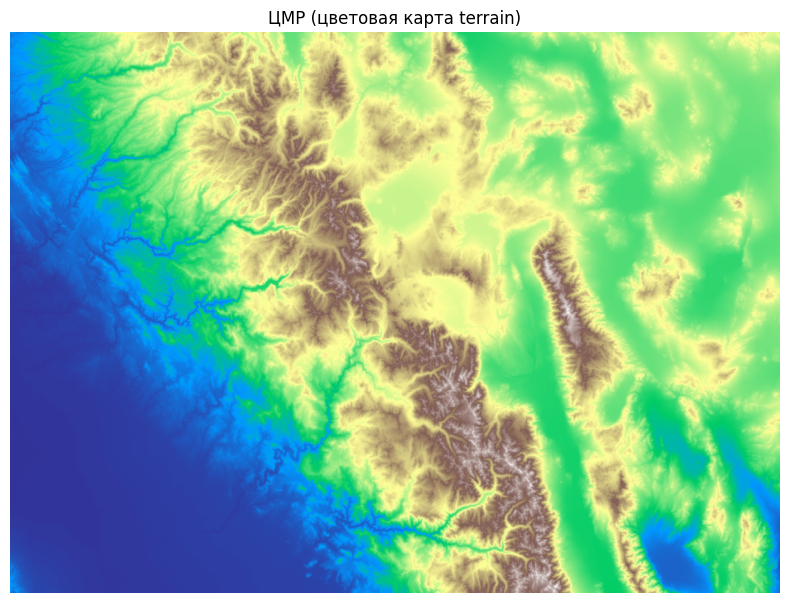

In [7]:
import rasterio.plot
fig, ax = plt.subplots(figsize=(8, 8))
rasterio.plot.show(src, ax=ax, cmap='terrain')
ax.set_title("ЦМР (цветовая карта terrain)")
ax.axis('off')
plt.tight_layout()
plt.show()

2. Откройте мультиспектральное изображение и визуализируйте первый канал с использованием подходящей цветовой карты.


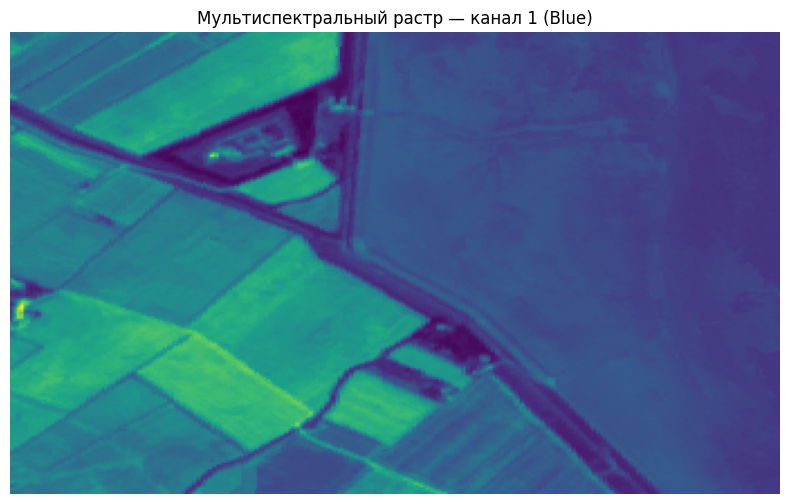

In [8]:
landsat_path = "https://github.com/opengeos/datasets/releases/download/raster/cog.tif"
src_landsat = rasterio.open(landsat_path)
fig, ax = plt.subplots(figsize=(8, 8))
rasterio.plot.show((src_landsat, 1), ax=ax, cmap='viridis')
ax.set_title("Мультиспектральный растр — канал 1 (Blue)")
ax.axis('off')
plt.tight_layout()
plt.show()

3. Объедините несколько каналов из мультиспектрального изображения (например, Красный, Зеленый и Синий) и совместите их в один массив для создания RGB-композитного изображения.

>*Примечание:*
>
> При работе с многоканальными растровыми изображениями, особенно в формате COG.TIFF (Cloud Optimized GeoTIFF), может возникнуть проблема с некорректным отображением псевдоцветного изображения. Это связано с тем, что разные каналы могут иметь различные диапазоны значений пикселей.
>
> Для корректной визуализации на шаге 2 необходимо применить нормализацию к каждому каналу перед отображением.



Включите следующую функцию в ваш код:

```python
# Функция для нормализации канала в диапазон от 0 до 1
def normalize(band):
    band_min = band.min()
    band_max = band.max()
    band_norm = (band - band_min) / (band_max - band_min)
    return band_norm
```

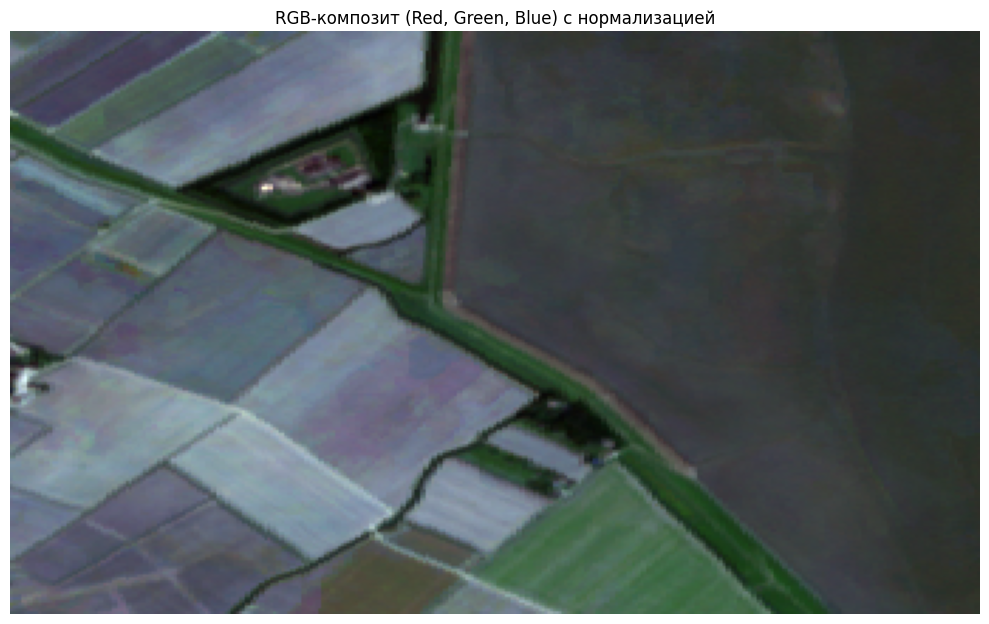

In [9]:
# Функция для нормализации канала в диапазон от 0 до 1
def normalize(band):
    band_min = band.min()
    band_max = band.max()
    band_norm = (band - band_min) / (band_max - band_min)
    return band_norm
red = src_landsat.read(3)
green = src_landsat.read(2)
blue = src_landsat.read(1)

# нормализуем каждый канал
red_norm = normalize(red)
green_norm = normalize(green)
blue_norm = normalize(blue)

# объединяем в массив (H, W, 3)
rgb = np.stack([red_norm, green_norm, blue_norm], axis=-1)

# визуализируем RGB-композит
fig, ax = plt.subplots(figsize=(10, 10))
ax.imshow(rgb)
ax.set_title("RGB-композит (Red, Green, Blue) с нормализацией")
ax.axis('off')
plt.tight_layout()
plt.show()

---



### **Задание 3. Обрезка растра с использованием индексации массива**



1. Откройте мультиспектральное изображение и обрежьте его с использованием спискового среза (указав диапазоны строк и столбцов).


In [10]:

src_landsat = rasterio.open(landsat_path)
data = src_landsat.read()
print("Исходная форма:", data.shape)
clipped = data[:, 50:150, 100:280]
print("Форма после обрезки:", clipped.shape)

Исходная форма: (4, 206, 343)
Форма после обрезки: (4, 100, 180)


2. Визуализируйте обрезанную часть изображения с использованием matplotlib, чтобы убедиться в корректном результате.


>*Примечание:*
>
> При работе с многоканальными растровыми изображениями, особенно в формате COG.TIFF (Cloud Optimized GeoTIFF), может возникнуть проблема с некорректным отображением псевдоцветного изображения. Это связано с тем, что разные каналы могут иметь различные диапазоны значений пикселей.
>
> Для корректной визуализации на шаге 2 необходимо применить нормализацию к каждому каналу перед отображением.



Включите следующую функцию в ваш код:

```python
# Функция для нормализации канала в диапазон от 0 до 1
def normalize(band):
    band_min = band.min()
    band_max = band.max()
    band_norm = (band - band_min) / (band_max - band_min)
    return band_norm
```

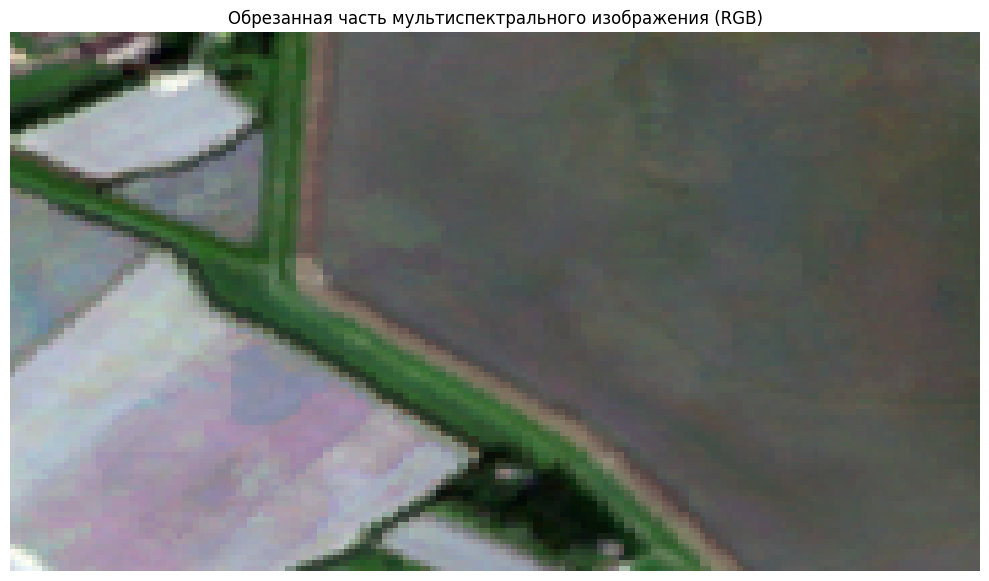

In [12]:
clip_rgb = np.stack([normalize(clipped[2]),
                     normalize(clipped[1]),
                     normalize(clipped[0])], axis=-1)

fig, ax = plt.subplots(figsize=(10, 6))
ax.imshow(clip_rgb)
ax.set_title("Обрезанная часть мультиспектрального изображения (RGB)")
ax.axis('off')
plt.tight_layout()
plt.show()

3. Сохраните обрезанное подмножество растра в новый файл с именем `clipped_multispectral.tif`.

In [13]:
from rasterio.windows import Window, transform as window_transform


win = Window(col_off=100, row_off=50, width=180, height=100)

# вычисляю новую аффинную матрицу для обрезанной области,
# чтобы файл остался геопривязанным (правильные координаты границ)
clip_transform = window_transform(win, src_landsat.transform)

# копирую метаданные исходного растра и обновляем размеры и transform
out_meta = src_landsat.meta.copy()
out_meta.update(height=clipped.shape[1], width=clipped.shape[2], transform=clip_transform)

# записываю обрезанное подмножество в новый GeoTIFF
with rasterio.open("clipped_multispectral.tif", "w", **out_meta) as dst:
    dst.write(clipped)

print("Сохранено: clipped_multispectral.tif", clipped.shape)

Сохранено: clipped_multispectral.tif (4, 100, 180)


---



### **Задание 4. Вычисление NDWI (калькуляция каналов)**



1. Откройте мультиспектральное изображение и извлеките каналы Green (Зеленый) и Ближний инфракрасный (NIR).


In [14]:
# Green — канал 2, NIR (ближний ИК) — канал 4
green = src_landsat.read(2).astype("float64")
nir = src_landsat.read(4).astype("float64")
print("Green:", green.shape, "| NIR:", nir.shape)

Green: (206, 343) | NIR: (206, 343)


2. Вычислите Нормализованный разностный водный индекс ([NDWI](https://en.wikipedia.org/wiki/Normalized_difference_water_index)) по формуле:

    NDWI = (Green - NIR) / (Green + NIR)

In [15]:
# Нормализованный разностный водный индекс
# NDWI = (Green - NIR) / (Green + NIR)
ndwi = (green - nir) / (green + nir)
print("Диапазон NDWI: от %.3f до %.3f" % (ndwi.min(), ndwi.max()))

Диапазон NDWI: от -0.622 до 0.477


3. Визуализируйте результат NDWI с использованием цветовой карты, подходящей для воды (например, cmap='Blues'), чтобы выделить водные объекты.


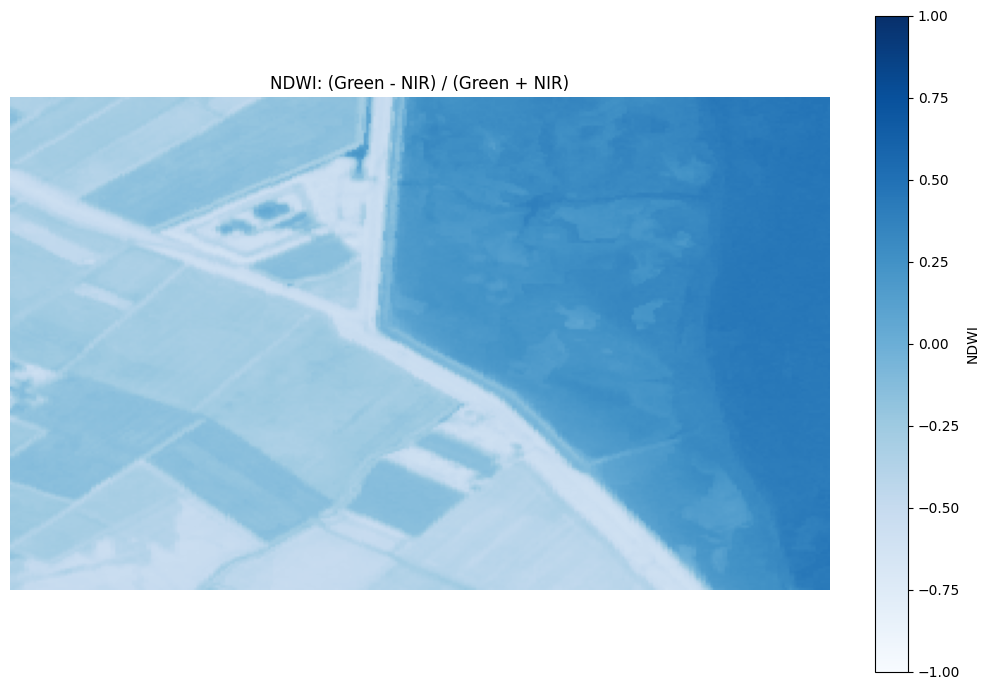

In [16]:
fig, ax = plt.subplots(figsize=(10, 7))
im = ax.imshow(ndwi, cmap="Blues", vmin=-1, vmax=1)
plt.colorbar(im, ax=ax, fraction=0.046, label="NDWI")
ax.set_title("NDWI: (Green - NIR) / (Green + NIR)")
ax.axis("off")
plt.tight_layout()
plt.show()



4. Сохраните полученное изображение NDWI как новый растровый файл с именем ndwi.tif.

In [17]:
# метаданные беру из исходного растра, но ставлю 1 канал и float32
ndwi_meta = src_landsat.meta.copy()
ndwi_meta.update(dtype="float32", count=1, compress="lzw")

with rasterio.open("ndwi.tif", "w", **ndwi_meta) as dst:
    dst.write(ndwi.astype("float32"), 1)

print("Сохранено: ndwi.tif")

Сохранено: ndwi.tif


---



### **Задание 5. Перепроецирование растровых данных**



1. Перепроецируйте одноканальный растр ЦМР из его исходной СК в EPSG:4326 (WGS 84) с использованием функции `rasterio.warp.reproject`.


In [18]:
from rasterio.warp import calculate_default_transform, reproject, Resampling

dst_crs = "EPSG:4326"  # WGS 84

# новая матрица преобразования и размеры растра в новой СК
transform, width, height = calculate_default_transform(
    src.crs, dst_crs, src.width, src.height, *src.bounds)

# метаданные выходного файла: новая СК, transform и размеры
kwargs = src.meta.copy()
kwargs.update(crs=dst_crs, transform=transform, width=width, height=height)
print("Размеры в новой СК:", width, "x", height)

# перепроецирование
destination = np.zeros((height, width), dtype=src.dtypes[0])
reproject(
    source=rasterio.band(src, 1),
    destination=destination,
    src_transform=src.transform,
    src_crs=src.crs,
    dst_transform=transform,
    dst_crs=dst_crs,
    resampling=Resampling.bilinear,
)

Размеры в новой СК: 4575 x 2642


(array([[ 582,  586,  594, ..., 1995, 2017, 2029],
        [ 600,  609,  617, ..., 1969, 1987, 2003],
        [ 612,  621,  627, ..., 1948, 1970, 1995],
        ...,
        [ 550,  543,  567, ...,  452,  448,  443],
        [ 534,  535,  561, ...,  455,  449,  441],
        [ 522,  521,  543, ...,  447,  449,  447]],
       shape=(2642, 4575), dtype=int16),
 Affine(0.0007543273324700005, 0.0, -120.75592734935736,
        0.0, -0.0007543273324700005, 38.62692343418839))

2. Сохраните перепроецированный растр в новый файл GeoTIFF с именем `reprojected_dem.tif`.


In [19]:
with rasterio.open("reprojected_dem.tif", "w", **kwargs) as dst_file:
    dst_file.write(destination, 1)

print("Сохранено: reprojected_dem.tif")

Сохранено: reprojected_dem.tif


3. Визуализируйте как исходный, так и перепроецированный наборы данных ЦМР, чтобы сравнить, как перепроецирование влияет на пространственное покрытие и разрешение.

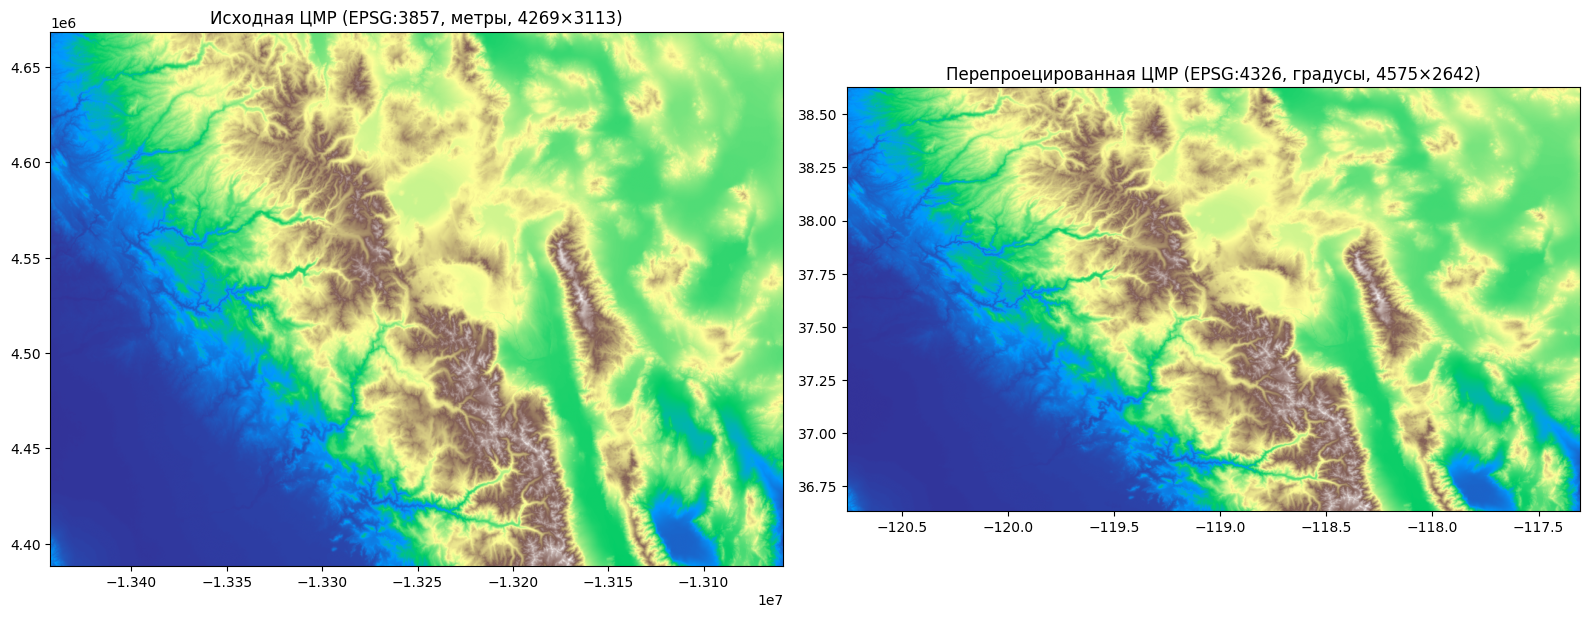

Исходное разрешение (м): (90.0, 89.99579177642138)
Новое разрешение (градусы): (0.0007543273324700005, 0.0007543273324700005)
Новые границы: BoundingBox(left=-120.75592734935736, bottom=36.63399062180265, right=-117.30487980330712, top=38.62692343418839)


In [21]:
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# исходный растр: СК EPSG:3857, разрешение ~90 м
rasterio.plot.show(src, ax=axes[0], cmap="terrain")
axes[0].set_title("Исходная ЦМР (EPSG:3857, метры, %d×%d)" % (src.width, src.height))

# перепроецированный растр: массив numpy + transform передаём отдельно
rasterio.plot.show(destination, transform=transform, ax=axes[1], cmap="terrain")
axes[1].set_title("Перепроецированная ЦМР (EPSG:4326, градусы, %d×%d)" % (width, height))

plt.tight_layout()
plt.show()

print("Исходное разрешение (м):", src.res)
print("Новое разрешение (градусы):", (abs(transform.a), abs(transform.e)))
print("Новые границы:", rasterio.open('reprojected_dem.tif').bounds)

---